In [29]:
import math
import random

In [20]:
class Value:
    def __init__(self, data, _children=(), _op='', label = ''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        
        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward
        return out

    def __neg__(self):
        out = Value(-self.data, (self, ), '-')

        def _backward():
            self.grad += -out.grad

        out._backward = _backward
        return out
        
    def __div__(self, other):
        if other.data == 0:
            raise ZeroDivisionError("Value 的除数不能为 0")
        
        out = Value(self.data / other.data, (self, other), '/')

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward    
        return out 

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), 'tanh')
        
        def _backward():
            self.grad += (1 - t**2)*out.grad

        out._backward = _backward
        return out
        
    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)

                for child in v._prev:
                    build_topo(child)

                topo.append(v)
                
        build_topo(self)

        self.grad = 1.0

        for node in reversed(topo):
            node._backward()

a = Value(1.0, label='a')
b = Value(2.0, label='b')
c = Value(3.0, label='c')

d = a + b; d.label = 'd'
e = d * c; e.label = 'e'

f = Value(0.1, label='f')
L = e * f; L.label = 'L'

O = L.tanh(); O.label = 'O'

# 执行反向传播
O.backward()

In [31]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(0.0)

    def __call__(self, x):
        if len(x) != len(self.w):
            raise ValueError(f"期望 {len(self.w)} 个输入，实际收到 {len(x)} 个")
            
        res = sum([(self.w[i] * (xi if isinstance(xi, Value) else Value(xi)) ) for i, xi in enumerate(x)], self.b)
        return res.tanh()
        
    def parameters(self):
        return [*self.w, self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x): 
        return [n(x) for n in self.neurons]

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP:
    def __init__(self, nin, data):
        inputs = [nin, *data]
        self.layers = [Layer(inputs[i], d) for i, d in enumerate(data)]

    def __call__(self, x):
        result = x
        for l in self.layers:
            result = l(result)
        return result

    def parameters(self):
        return [p for l in self.layers for p in l.parameters()]
        
            

In [34]:
model = MLP(4, [2, 3, 5])
model([1,2,3,4])

[Value(data=0.1699241457531811),
 Value(data=0.2223108927473737),
 Value(data=-0.5579638902621082),
 Value(data=-0.4359846639016744),
 Value(data=0.2474737041270471)]

In [17]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        
        dot.node(name = uid, label = "{ %s | data %.4f ｜ grad %.4f }" % (n.label, n.data, n.grad ), shape='record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)
        
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
            
    return dot

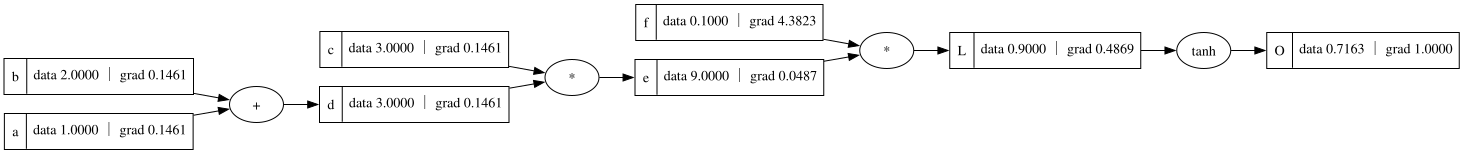

In [18]:
draw_dot(O)